In [1]:
import pandas as pd
import numpy as np

# Données entièrement fictives : expérience client digitale et communication bancaire
rng = np.random.default_rng(314)
n = 6000

age = rng.integers(18, 81, n)
segment = rng.choice(["Particulier", "Professionnel", "Premium"], n, p=[0.70, 0.18, 0.12])
canal_prefere = rng.choice(["Application", "Site web", "Agence", "Téléphone"], n, p=[0.50, 0.20, 0.18, 0.12])
anciennete_ans = rng.integers(0, 31, n)
conseiller_dedie = np.where(segment == "Premium", "Oui", rng.choice(["Oui", "Non"], n, p=[0.25, 0.75]))

connexions_app_mois = rng.poisson(np.where(canal_prefere == "Application", 14, 4))
nb_bugs_signales = rng.poisson(0.5, n)
temps_reponse_chat_min = np.clip(rng.lognormal(1.6, 0.8, n), 0.5, 240).round(1)
nb_emails_recus_mois = rng.poisson(7, n)
nb_notifications_mois = rng.poisson(10, n)
taux_ouverture_emails = rng.beta(2, 4, n).round(2)
nb_reclamations_12m = rng.poisson(0.35, n)

# Probabilité d'insatisfaction (règle cachée)
volume_com = nb_emails_recus_mois + nb_notifications_mois
logit = (
    -2.6
    + 0.45 * nb_bugs_signales
    + 1.4 * (temps_reponse_chat_min > 15)            # au-delà de 15 min d'attente, ça bascule
    + 0.80 * nb_reclamations_12m
    + 0.035 * np.maximum(volume_com - 18, 0) ** 2   # trop de sollicitations irrite...
    + 0.6 * (volume_com < 9)                         # ...trop peu aussi
    + 1.8 * ((age >= 60) & (canal_prefere == "Application"))  # seniors poussés vers l'appli
    - 0.6 * (conseiller_dedie == "Oui")
    - 0.025 * anciennete_ans
    - 0.8 * taux_ouverture_emails
    + 0.3 * (segment == "Professionnel")
)
prob = 1 / (1 + np.exp(-logit))
insatisfait = rng.binomial(1, prob)

df = pd.DataFrame({
    "id_client": [f"CLI_{i:05d}" for i in range(1, n + 1)],
    "age": age,
    "segment": segment,
    "canal_prefere": canal_prefere,
    "anciennete_ans": anciennete_ans,
    "conseiller_dedie": conseiller_dedie,
    "connexions_app_mois": connexions_app_mois,
    "nb_bugs_signales": nb_bugs_signales,
    "temps_reponse_chat_min": temps_reponse_chat_min,
    "nb_emails_recus_mois": nb_emails_recus_mois,
    "nb_notifications_mois": nb_notifications_mois,
    "taux_ouverture_emails": taux_ouverture_emails,
    "nb_reclamations_12m": nb_reclamations_12m,
    "insatisfait": insatisfait,
})

# Défauts volontaires à corriger
for col, frac in [("temps_reponse_chat_min", 0.06), ("canal_prefere", 0.02), ("taux_ouverture_emails", 0.03)]:
    idx = rng.choice(df.index, size=int(n * frac), replace=False)
    df.loc[idx, col] = np.nan

df = pd.concat([df, df.sample(20, random_state=314)], ignore_index=True)

path = "experience_client.csv"
df.to_csv(path, index=False)
print(path, df.shape, df["insatisfait"].value_counts().to_dict())

experience_client.csv (6020, 14) {0: 5136, 1: 884}


In [10]:
df = pd.read_csv("experience_client.csv")

In [11]:
df.head()

,id_client,age,segment,canal_prefere,anciennete_ans,conseiller_dedie,connexions_app_mois,nb_bugs_signales,temps_reponse_chat_min,nb_emails_recus_mois,nb_notifications_mois,taux_ouverture_emails,nb_reclamations_12m,insatisfait
0,CLI_00001,47,Premium,Agence,13,Oui,1,2,3.0,9,9,0.31,0,0
1,CLI_00002,76,Particulier,Application,21,Oui,12,2,12.7,7,14,0.12,0,1
2,CLI_00003,60,Particulier,Application,22,Non,16,1,3.3,7,11,0.33,0,0
3,CLI_00004,62,Professionnel,Téléphone,26,Non,4,0,4.5,9,11,0.11,0,0
4,CLI_00005,53,Professionnel,Téléphone,27,Oui,2,0,4.8,2,10,0.11,1,1


In [47]:
df["insatisfait"].value_counts(normalize=True)

insatisfait
0    0.853
1    0.147
Name: proportion, dtype: float64

In [12]:
df.shape

(6020, 14)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6020 entries, 0 to 6019
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_client               6020 non-null   str    
 1   age                     6020 non-null   int64  
 2   segment                 6020 non-null   str    
 3   canal_prefere           5898 non-null   str    
 4   anciennete_ans          6020 non-null   int64  
 5   conseiller_dedie        6020 non-null   str    
 6   connexions_app_mois     6020 non-null   int64  
 7   nb_bugs_signales        6020 non-null   int64  
 8   temps_reponse_chat_min  5658 non-null   float64
 9   nb_emails_recus_mois    6020 non-null   int64  
 10  nb_notifications_mois   6020 non-null   int64  
 11  taux_ouverture_emails   5840 non-null   float64
 12  nb_reclamations_12m     6020 non-null   int64  
 13  insatisfait             6020 non-null   int64  
dtypes: float64(2), int64(8), str(4)
memory usage: 658.6

In [14]:
df.describe()

,age,anciennete_ans,connexions_app_mois,nb_bugs_signales,temps_reponse_chat_min,nb_emails_recus_mois,nb_notifications_mois,taux_ouverture_emails,nb_reclamations_12m,insatisfait
count,6020.000000,6020.000000,6020.000000,6020.000000,5658.000000,6020.000000,6020.000000,5840.000000,6020.000000,6020.000000
mean,49.026412,15.048837,9.058140,0.493189,6.829392,7.030731,10.028904,0.332197,0.352326,0.146844
std,18.264904,8.991455,5.837667,0.706310,6.178410,2.633677,3.200634,0.176329,0.597903,0.353980
min,18.000000,0.000000,0.000000,0.000000,0.500000,0.000000,1.000000,0.010000,0.000000,0.000000
25%,33.000000,7.000000,4.000000,0.000000,2.900000,5.000000,8.000000,0.190000,0.000000,0.000000
50%,49.000000,15.000000,8.000000,0.000000,5.000000,7.000000,10.000000,0.320000,0.000000,0.000000
75%,65.000000,23.000000,14.000000,1.000000,8.600000,9.000000,12.000000,0.450000,1.000000,0.000000
max,80.000000,30.000000,30.000000,5.000000,73.600000,20.000000,24.000000,0.900000,4.000000,1.000000


In [16]:
df.isna().sum()

id_client                   0
age                         0
segment                     0
canal_prefere             122
anciennete_ans              0
conseiller_dedie            0
connexions_app_mois         0
nb_bugs_signales            0
temps_reponse_chat_min    362
nb_emails_recus_mois        0
nb_notifications_mois       0
taux_ouverture_emails     180
nb_reclamations_12m         0
insatisfait                 0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(20)

In [18]:
df.nunique()

id_client                 6000
age                         63
segment                      3
canal_prefere                4
anciennete_ans              31
conseiller_dedie             2
connexions_app_mois         30
nb_bugs_signales             6
temps_reponse_chat_min     320
nb_emails_recus_mois        20
nb_notifications_mois       23
taux_ouverture_emails       90
nb_reclamations_12m          5
insatisfait                  2
dtype: int64

In [19]:
df = df.drop_duplicates()

In [21]:
df.shape

(6000, 14)

In [22]:
df.head()

,id_client,age,segment,canal_prefere,anciennete_ans,conseiller_dedie,connexions_app_mois,nb_bugs_signales,temps_reponse_chat_min,nb_emails_recus_mois,nb_notifications_mois,taux_ouverture_emails,nb_reclamations_12m,insatisfait
0,CLI_00001,47,Premium,Agence,13,Oui,1,2,3.0,9,9,0.31,0,0
1,CLI_00002,76,Particulier,Application,21,Oui,12,2,12.7,7,14,0.12,0,1
2,CLI_00003,60,Particulier,Application,22,Non,16,1,3.3,7,11,0.33,0,0
3,CLI_00004,62,Professionnel,Téléphone,26,Non,4,0,4.5,9,11,0.11,0,0
4,CLI_00005,53,Professionnel,Téléphone,27,Oui,2,0,4.8,2,10,0.11,1,1


In [24]:
x = df.drop("insatisfait", axis=1)
y = df["insatisfait"]

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

In [28]:
numeric_features = [
    "age",
    "anciennete_ans",
    "connexions_app_mois",
    "nb_bugs_signales",
    "temps_reponse_chat_min",
    "nb_emails_recus_mois",
    "nb_notifications_mois",
    "taux_ouverture_emails",
    "nb_reclamations_12m"
]

categorical_features = [
    "segment",
    "canal_prefere",
    "conseiller_dedie"
]

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [31]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [34]:
from sklearn.linear_model import LogisticRegression

In [36]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [37]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['id_client','age','segment',...,'nb_notifications_mois', 'taux_ouverture_emails','nb_reclamations_12m']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

In [40]:
model.named_steps["classifier"].n_iter_

array([26], dtype=int32)

In [42]:
y_pred = model.predict(X_test)
print("Insatisfait prédits :", y_pred.sum())
print("Insatisfait réels :", y_test.sum())

Insatisfait prédits : 27
Insatisfait réels : 176


In [43]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['id_client','age','segment',...,'nb_notifications_mois', 'taux_ouverture_emails','nb_reclamations_12m']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

In [44]:
model.named_steps["classifier"].n_iter_

array([12], dtype=int32)

In [45]:
y_pred = model.predict(X_test)
print("Insatisfait prédits :", y_pred.sum())
print("Insatisfait réels :", y_test.sum())

Insatisfait prédits : 443
Insatisfait réels : 176


In [48]:
print("Insatisfait prédits :", y_pred.sum())
print("Insatisfait réels :", y_test.sum())
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC :", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

Insatisfait prédits : 443
Insatisfait réels : 176
[[705 319]
 [ 52 124]]
              precision    recall  f1-score   support

           0       0.93      0.69      0.79      1024
           1       0.28      0.70      0.40       176

    accuracy                           0.69      1200
   macro avg       0.61      0.70      0.60      1200
weighted avg       0.84      0.69      0.73      1200

AUC : 0.7666348544034092


 seuil  clients_signales  insatisfaits_detectes  fausses_alertes  insatisfaits_manques  rappel  precision  cout_total
  0.30               856                    162              694                    14   0.920      0.189       14520
  0.35               742                    155              587                    21   0.881      0.209       13650
  0.40               631                    145              486                    31   0.824      0.230       13185
  0.45               534                    138              396                    38   0.784      0.258       12570
  0.50               443                    124              319                    52   0.705      0.280       12885
  0.55               348                    111              237                    65   0.631      0.319       13020
  0.60               265                     91              174                    85   0.517      0.343       14175
  0.65               198                     82         

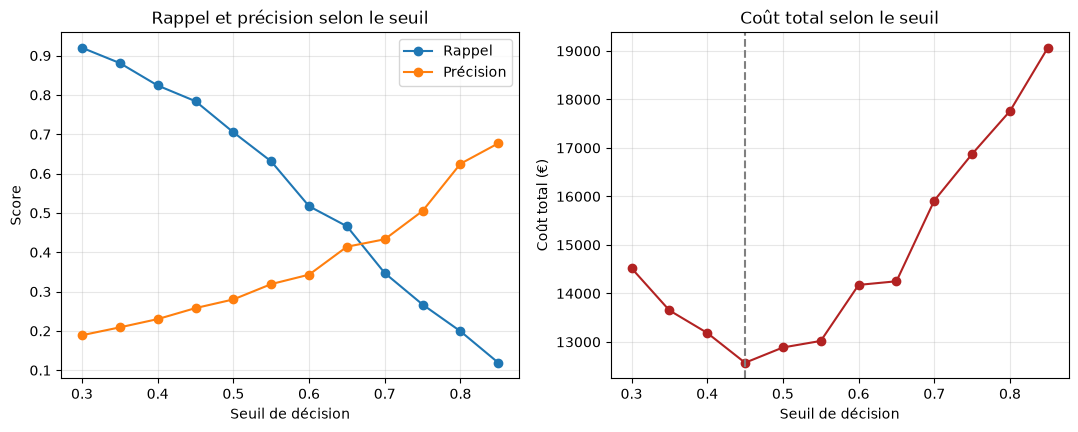

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

probas = model.predict_proba(X_test)[:, 1]

# 1. Tableau des résultats pour chaque seuil
lignes = []
for seuil in np.arange(0.30, 0.86, 0.05):
    pred = (probas >= seuil).astype(int)
    vp = ((pred == 1) & (y_test == 1)).sum()   # insatisfaits détectés
    fp = ((pred == 1) & (y_test == 0)).sum()   # satisfaits signalés à tort
    fn = ((pred == 0) & (y_test == 1)).sum()   # insatisfaits manqués
    lignes.append({
        "seuil": round(seuil, 2),
        "clients_signales": pred.sum(),
        "insatisfaits_detectes": vp,
        "fausses_alertes": fp,
        "insatisfaits_manques": fn,
        "rappel": round(vp / (vp + fn), 3),
        "precision": round(vp / pred.sum(), 3) if pred.sum() > 0 else np.nan,
    })
resultats = pd.DataFrame(lignes)

# 2. Coût total selon des hypothèses métier (à adapter)
COUT_CONTACT = 15           # coût d'un contact client (en €)
COUT_INSATISFAIT_MANQUE = 120  # perte estimée pour un insatisfait non traité (en €)
resultats["cout_total"] = (resultats["clients_signales"] * COUT_CONTACT
                           + resultats["insatisfaits_manques"] * COUT_INSATISFAIT_MANQUE)
print(resultats.to_string(index=False))

meilleur = resultats.loc[resultats["cout_total"].idxmin()]
print(f"\nSeuil le moins coûteux : {meilleur['seuil']} "
      f"(coût total : {meilleur['cout_total']:,.0f} €)")

# 3. Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(resultats["seuil"], resultats["rappel"], marker="o", label="Rappel")
ax1.plot(resultats["seuil"], resultats["precision"], marker="o", label="Précision")
ax1.set_xlabel("Seuil de décision"); ax1.set_ylabel("Score")
ax1.set_title("Rappel et précision selon le seuil"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(resultats["seuil"], resultats["cout_total"], marker="o", color="firebrick")
ax2.axvline(meilleur["seuil"], linestyle="--", color="grey")
ax2.set_xlabel("Seuil de décision"); ax2.set_ylabel("Coût total (€)")
ax2.set_title("Coût total selon le seuil"); ax2.grid(alpha=0.3)
plt.show()